## 0. Configuration and imports

In [1]:
import os, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from numpy.lib.stride_tricks import sliding_window_view
from sklearn.cluster import KMeans
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge, Lasso
from sklearn.metrics import mean_squared_error
from IPython.display import display

warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 180)

SEED = 42
np.random.seed(SEED)

DATA_DIR = os.environ.get(
    "CMAPSS_DIR",
    "/kaggle/input/datasets/tanmoypauldiat/cmapps-fd001-and-fd002"
)
OUT_DIR = "/kaggle/working/ridge_lasso_q1" if os.path.isdir("/kaggle/working") else "ridge_lasso_q1_outputs"
os.makedirs(OUT_DIR, exist_ok=True)

DATASETS = ["FD001", "FD002"]
MODELS = ["Ridge", "Lasso"]
WINDOWS = [5, 10, 20, 30, 50]
CONDITIONS = ["A", "B", "C", "D"]
N_FOLDS = 5
RUL_CAP = 125
MIN_EVAL_CYCLE = 50
TRAIN_STRIDE = 4

# Regularization strengths. These are fixed before evaluation.
# Features are standardized inside each fold before fitting either model.
RIDGE_ALPHA = 1.0
LASSO_ALPHA = 0.01
LASSO_MAX_ITER = 30000

# Three deterministic shuffle repetitions for Condition D.
D_SHUFFLE_SEEDS = [101, 202, 303]

print("Global seed:", SEED)
print("Data directory:", DATA_DIR)
print("Output directory:", OUT_DIR)

Global seed: 42
Data directory: /kaggle/input/datasets/tanmoypauldiat/cmapps-fd001-and-fd002
Output directory: /kaggle/working/ridge_lasso_q1


## 1. Load FD001 and FD002

In [2]:
def add_rul(df):
    df = df.sort_values(["unit_id", "cycle"]).reset_index(drop=True).copy()
    df["RUL"] = df.groupby("unit_id")["cycle"].transform("max") - df["cycle"]
    df["y"] = df["RUL"].clip(upper=RUL_CAP)
    return df

def read_rul(path, n_expected):
    r = pd.read_csv(path, header=None).apply(pd.to_numeric, errors="coerce").dropna()
    values = r.iloc[:, 0].to_numpy()
    if len(values) == n_expected + 1:
        values = values[1:]
    if len(values) != n_expected:
        raise ValueError(f"{path}: expected {n_expected} RUL values, found {len(values)}")
    return values

DATA = {}
for ds in DATASETS:
    train = add_rul(pd.read_csv(f"{DATA_DIR}/train_{ds}.csv"))
    test = pd.read_csv(f"{DATA_DIR}/test_{ds}.csv").sort_values(
        ["unit_id", "cycle"]
    ).reset_index(drop=True)

    rul = read_rul(f"{DATA_DIR}/RUL_{ds}.csv", test["unit_id"].nunique())
    sensor_cols = [c for c in train.columns if c.startswith("sensor")]
    sensors = [c for c in sensor_cols if train[c].std() > 0]
    settings = [c for c in train.columns
                if c not in ("unit_id", "cycle", "RUL", "y")
                and not c.startswith("sensor")]

    DATA[ds] = {
        "train": train, "test": test, "rul": rul,
        "sensors": sensors, "settings": settings,
        "n_regimes": 6 if ds == "FD002" else 1
    }

summary = []
for ds, d in DATA.items():
    summary.append({
        "Dataset": ds,
        "Train engines": d["train"].unit_id.nunique(),
        "Train rows": len(d["train"]),
        "Test engines": d["test"].unit_id.nunique(),
        "Test rows": len(d["test"]),
        "Sensors used": len(d["sensors"]),
        "Operating settings": len(d["settings"]),
        "Operating regimes": d["n_regimes"]
    })
display(pd.DataFrame(summary))

,Dataset,Train engines,Train rows,Test engines,Test rows,Sensors used,Operating settings,Operating regimes
0,FD001,100,20631,100,13096,19,3,1
1,FD002,260,53759,259,33991,21,3,6


## 2. Global seed and common five-fold protocol

Each dataset receives five engine-wise folds using the same deterministic procedure and `SEED = 42`. An engine is assigned wholly to one fold; observations from the same engine never appear in both training and validation partitions.

Because FD001 has 100 training engines and FD002 has 260, the engine IDs cannot be identical across datasets. What is shared is the seed, fold numbering, shuffling rule and balanced assignment procedure.

In [3]:
def make_engine_folds(engine_ids, seed=SEED, n_folds=N_FOLDS):
    engine_ids = np.array(sorted(engine_ids))
    rng = np.random.default_rng(seed)
    shuffled = engine_ids.copy()
    rng.shuffle(shuffled)
    fold_map = {int(engine): int(i % n_folds)
                for i, engine in enumerate(shuffled)}
    return fold_map

for ds, d in DATA.items():
    d["fold_of"] = make_engine_folds(d["train"]["unit_id"].unique())
    d["groups"] = d["train"].groupby("unit_id", sort=False).indices

    fold_table = (pd.Series(d["fold_of"], name="fold")
                  .rename_axis("unit_id").reset_index()
                  .groupby("fold").agg(engines=("unit_id", "nunique")))
    print(f"\n{ds} fold allocation")
    display(fold_table)


FD001 fold allocation


,engines
fold,
0,20
1,20
2,20
3,20
4,20



FD002 fold allocation


,engines
fold,
0,52
1,52
2,52
3,52
4,52


## 3. Operating-condition normalizer and temporal feature construction

In [4]:
class OperatingConditionNormalizer:
    """Fit on training engines only; FD001 uses one regime, FD002 uses six K-means regimes."""
    def __init__(self, n_regimes, settings):
        self.k = n_regimes
        self.settings = settings

    def _regime(self, df):
        if self.k == 1:
            return np.zeros(len(df), dtype=int)
        settings = df[self.settings].to_numpy()
        return self.kmeans.predict((settings - self.settings_mean) / self.settings_std)

    def fit(self, df, sensors):
        self.sensors = list(sensors)
        X = df[self.sensors].to_numpy()

        if self.k > 1:
            S = df[self.settings].to_numpy()
            self.settings_mean = S.mean(axis=0)
            self.settings_std = S.std(axis=0) + 1e-9
            self.kmeans = KMeans(n_clusters=self.k, n_init=10, random_state=SEED)
            self.kmeans.fit((S - self.settings_mean) / self.settings_std)

        regime = self._regime(df)
        global_mean = X.mean(axis=0)
        global_std = X.std(axis=0) + 1e-9

        self.mean = np.zeros((self.k, len(self.sensors)))
        self.std = np.ones((self.k, len(self.sensors)))

        for r in range(self.k):
            mask = regime == r
            if mask.sum() > 10:
                self.mean[r] = X[mask].mean(axis=0)
                sd = X[mask].std(axis=0)
                self.std[r] = np.where(sd < 1e-9, 1.0, sd)
            else:
                self.mean[r] = global_mean
                self.std[r] = global_std
        return self

    def transform(self, df):
        regime = self._regime(df)
        return (df[self.sensors].to_numpy() - self.mean[regime]) / self.std[regime]


def window_features(W, condition, rng=None):
    """W shape: (n_windows, n_sensors, L), oldest reading first."""
    if condition == "A":
        return W[:, :, -1]

    features = [
        W.mean(axis=2),
        W.std(axis=2),
        W.min(axis=2),
        W.max(axis=2),
        np.median(W, axis=2)
    ]

    if condition in ("C", "D"):
        if condition == "D":
            if rng is None:
                raise ValueError("A random generator is required for condition D.")
            order = rng.random((W.shape[0], W.shape[2])).argsort(axis=1)
            W = np.take_along_axis(W, order[:, None, :], axis=2)

        L = W.shape[2]
        time_index = np.arange(L) - (L - 1) / 2
        slope = (W * time_index).sum(axis=2) / (time_index ** 2).sum()
        differences = np.diff(W, axis=2)

        features.extend([
            slope,
            W[:, :, -1] - W[:, :, 0],
            differences.std(axis=2),
            np.abs(differences).mean(axis=2)
        ])

    return np.concatenate(features, axis=1)


def build_windows(X_normalized, groups, units, L, condition,
                  start_cycle, stride, rng=None):
    feature_blocks, row_blocks = [], []

    for unit in units:
        positions = groups[unit]
        n = len(positions)
        end_positions = np.arange(max(L, start_cycle) - 1, n, stride)

        if len(end_positions) == 0:
            continue

        windows = sliding_window_view(
            X_normalized[positions], L, axis=0
        )[end_positions - (L - 1)]

        feature_blocks.append(window_features(windows, condition, rng))
        row_blocks.append(positions[end_positions])

    if not feature_blocks:
        return np.empty((0, X_normalized.shape[1])), np.array([], dtype=int)

    return np.vstack(feature_blocks), np.concatenate(row_blocks)


def make_regressor(model_name):
    if model_name == "Ridge":
        return make_pipeline(
            StandardScaler(),
            Ridge(alpha=RIDGE_ALPHA)
        )
    if model_name == "Lasso":
        return make_pipeline(
            StandardScaler(),
            Lasso(alpha=LASSO_ALPHA, max_iter=LASSO_MAX_ITER, random_state=SEED)
        )
    raise ValueError(model_name)


def rmse(y_true, y_pred):
    return float(np.sqrt(mean_squared_error(y_true, y_pred)))


def nasa_terms(y_true, y_pred):
    # d = prediction - truth; late predictions (d > 0) receive the steeper penalty.
    d = np.asarray(y_pred) - np.asarray(y_true)
    return np.where(d < 0, np.exp(-d / 13.0) - 1,
                    np.exp(d / 10.0) - 1)


def nasa_score(y_true, y_pred):
    return float(nasa_terms(y_true, y_pred).sum())

## 4. Cross-validation: Ridge and Lasso only

For each fold, the normalizer and feature standardizer are fitted using training engines only. The validation fold contains entirely unseen engines.

- Conditions A, B and C are evaluated for every window length.
- Condition D is evaluated using three fixed shuffle seeds; these repetitions are averaged for reporting.
- Validation metrics are computed over all eligible cycles from cycle 50 onward.
- The same folds are reused for every model, condition and window length.

In [5]:
def run_cross_validation(dataset):
    d = DATA[dataset]
    train = d["train"]
    sensors = d["sensors"]
    groups = d["groups"]
    fold_of = d["fold_of"]

    unit_values = np.array(sorted(fold_of))
    unit_folds = np.array([fold_of[u] for u in unit_values])

    unit_arr = train["unit_id"].to_numpy()
    y_all = train["y"].to_numpy()

    records = []
    start_time = time.time()

    for fold in range(N_FOLDS):
        train_units = unit_values[unit_folds != fold]
        valid_units = unit_values[unit_folds == fold]

        train_rows_mask = np.isin(unit_arr, train_units)
        normalizer = OperatingConditionNormalizer(
            d["n_regimes"], d["settings"]
        ).fit(train.loc[train_rows_mask], sensors)

        X_normalized = normalizer.transform(train)

        for condition in ["A", "B", "C", "D"]:
            for L in ([1] if condition == "A" else WINDOWS):
                shuffle_seeds = D_SHUFFLE_SEEDS if condition == "D" else [None]

                for shuffle_seed in shuffle_seeds:
                    rng = (np.random.default_rng(shuffle_seed + 1000 * fold)
                           if shuffle_seed is not None else None)

                    X_train, train_rows = build_windows(
                        X_normalized, groups, train_units, L, condition,
                        start_cycle=L, stride=TRAIN_STRIDE, rng=rng
                    )
                    X_valid, valid_rows = build_windows(
                        X_normalized, groups, valid_units, L, condition,
                        start_cycle=MIN_EVAL_CYCLE, stride=1, rng=rng
                    )

                    y_train = y_all[train_rows]
                    y_valid = y_all[valid_rows]

                    for model_name in MODELS:
                        model = make_regressor(model_name)
                        model.fit(X_train, y_train)
                        predictions = np.clip(model.predict(X_valid), 0, RUL_CAP)

                        records.append({
                            "dataset": dataset,
                            "model": model_name,
                            "condition": condition,
                            "window": L,
                            "shuffle_seed": shuffle_seed,
                            "fold": fold,
                            "n_validation_rows": len(y_valid),
                            "rmse": rmse(y_valid, predictions),
                            "nasa_score": nasa_score(y_valid, predictions),
                            "nasa_per_row": nasa_score(y_valid, predictions) / len(y_valid)
                        })

        print(f"{dataset}: fold {fold + 1}/{N_FOLDS} complete "
              f"({time.time() - start_time:.1f}s)")

    return pd.DataFrame(records)


cv_parts = [run_cross_validation(ds) for ds in DATASETS]
CV_RESULTS = pd.concat(cv_parts, ignore_index=True)
CV_RESULTS.to_csv(f"{OUT_DIR}/cv_fold_results.csv", index=False)
display(CV_RESULTS.head())

FD001: fold 1/5 complete (231.5s)
FD001: fold 2/5 complete (445.3s)
FD001: fold 3/5 complete (684.2s)
FD001: fold 4/5 complete (917.0s)
FD001: fold 5/5 complete (1173.2s)
FD002: fold 1/5 complete (301.9s)
FD002: fold 2/5 complete (600.6s)
FD002: fold 3/5 complete (883.1s)
FD002: fold 4/5 complete (1148.1s)
FD002: fold 5/5 complete (1436.6s)


,dataset,model,condition,window,shuffle_seed,fold,n_validation_rows,rmse,nasa_score,nasa_per_row
0,FD001,Ridge,A,1,NaN,0,3277,22.054011,36416.539070,11.112767
1,FD001,Lasso,A,1,NaN,0,3277,22.055308,36419.143509,11.113562
2,FD001,Ridge,B,5,NaN,0,3277,21.855376,35801.898381,10.925205
3,FD001,Lasso,B,5,NaN,0,3277,21.822318,35541.782630,10.845829
4,FD001,Ridge,B,10,NaN,0,3277,22.067113,38038.811483,11.607816


## 5. Summarise cross-validation results

In [6]:
# Average the three shuffled-window repetitions within each fold first.
CV_FOLD = (CV_RESULTS.groupby(
    ["dataset", "model", "condition", "window", "fold"], as_index=False
    )[["rmse", "nasa_score", "nasa_per_row"]].mean())

CV_SUMMARY = (CV_FOLD.groupby(
    ["dataset", "model", "condition", "window"], as_index=False
).agg(
    rmse_mean=("rmse", "mean"),
    rmse_sd=("rmse", "std"),
    nasa_mean=("nasa_score", "mean"),
    nasa_sd=("nasa_score", "std"),
    nasa_per_row_mean=("nasa_per_row", "mean"),
    nasa_per_row_sd=("nasa_per_row", "std")
))

CV_SUMMARY["rmse_mean_sd"] = CV_SUMMARY.apply(
    lambda r: f"{r.rmse_mean:.3f} ± {r.rmse_sd:.3f}", axis=1
)
display(CV_SUMMARY.sort_values(["dataset", "model", "condition", "window"]))
CV_SUMMARY.to_csv(f"{OUT_DIR}/cv_summary.csv", index=False)

,dataset,model,condition,window,rmse_mean,rmse_sd,nasa_mean,nasa_sd,nasa_per_row_mean,nasa_per_row_sd,rmse_mean_sd
0,FD001,Lasso,A,1,21.486039,1.007335,33404.047373,9396.053482,10.655366,3.007271,21.486 ± 1.007
1,FD001,Lasso,B,5,21.302717,1.128019,33331.300012,10360.140564,10.636000,3.317413,21.303 ± 1.128
2,FD001,Lasso,B,10,21.780211,1.038302,37235.475505,10890.568150,11.917324,3.685688,21.780 ± 1.038
3,FD001,Lasso,B,20,21.757060,1.169069,37351.711195,9282.254162,11.975226,3.366146,21.757 ± 1.169
4,FD001,Lasso,B,30,21.082512,1.049306,31050.862545,6852.838804,9.930093,2.378388,21.083 ± 1.049
...,...,...,...,...,...,...,...,...,...,...,...
59,FD002,Ridge,D,5,20.819867,1.603874,94150.592789,23601.544692,11.523520,3.061344,20.820 ± 1.604
60,FD002,Ridge,D,10,21.131515,1.653558,106143.330618,27677.124247,12.988095,3.570298,21.132 ± 1.654
61,FD002,Ridge,D,20,21.887718,1.701049,126367.478920,36211.479030,15.428714,4.471641,21.888 ± 1.701
62,FD002,Ridge,D,30,22.172261,1.696348,116304.165679,35289.620536,14.227353,4.435702,22.172 ± 1.696


## 6. Plot cross-validation RMSE

Each point is the mean RMSE across the five held-out engine folds; error bars show one fold standard deviation.

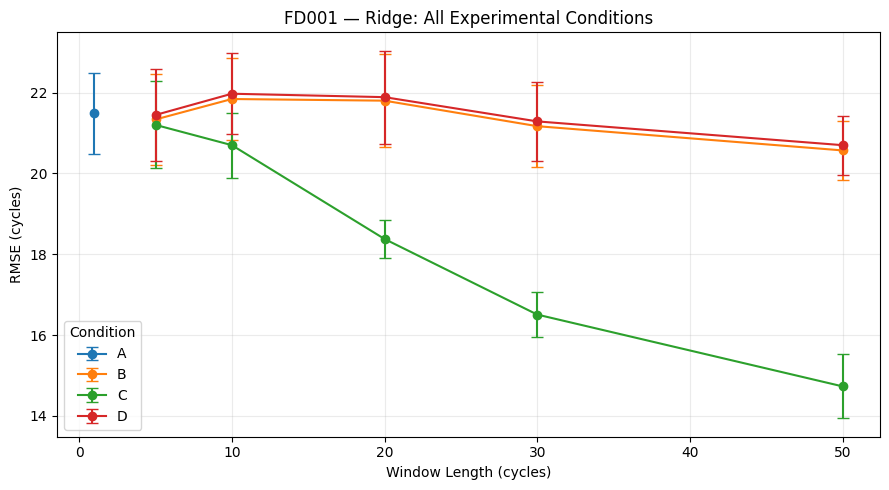

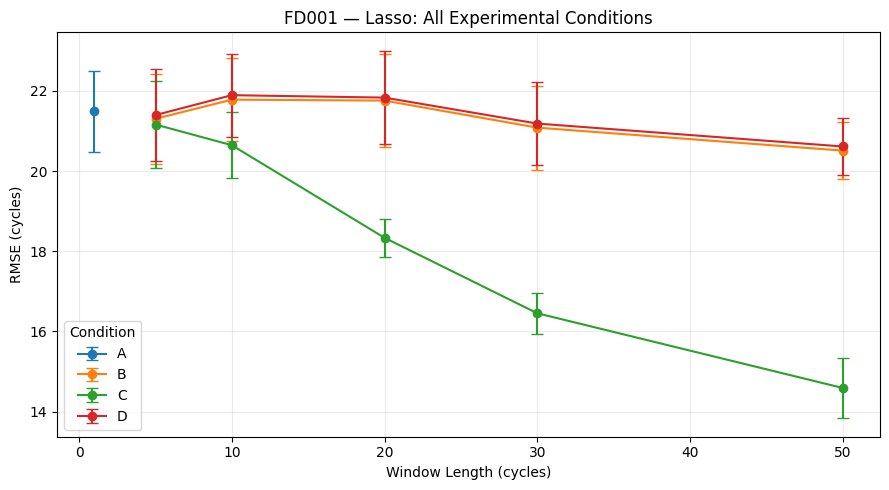

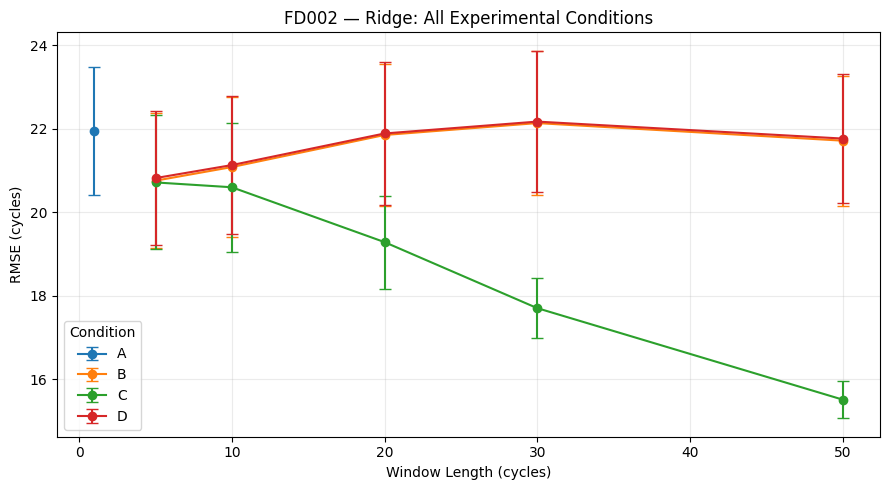

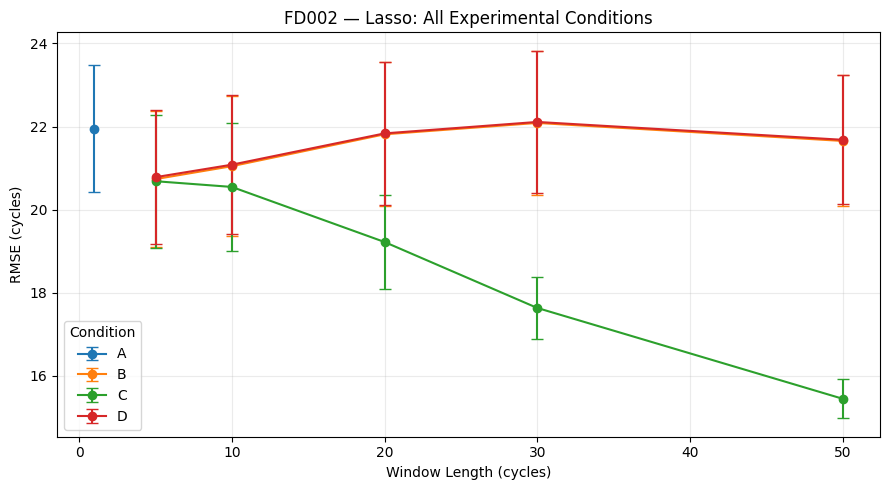

In [14]:
for ds in DATASETS:
    for model_name in MODELS:

        fig, ax = plt.subplots(figsize=(9, 5))

        subset = CV_SUMMARY[
            (CV_SUMMARY.dataset == ds) &
            (CV_SUMMARY.model == model_name)
        ]

        for condition in ["A", "B", "C", "D"]:
            part = subset[
                subset.condition == condition
            ].sort_values("window")

            ax.errorbar(
                part.window,
                part.rmse_mean,
                yerr=part.rmse_sd,
                marker="o",
                capsize=4,
                label=condition
            )

        ax.set_title(
            f"{ds} — {model_name}: All Experimental Conditions"
        )
        ax.set_xlabel("Window Length (cycles)")
        ax.set_ylabel("RMSE (cycles)")
        ax.grid(alpha=0.25)
        ax.legend(title="Condition")

        plt.tight_layout()
        plt.savefig(
            f"{OUT_DIR}/{ds}_{model_name}_cv_rmse.png",
            dpi=150
        )
        plt.show()

## 7. Official test-set evaluation

For each dataset, model and condition A/B/C, select the window length with the lowest **cross-validation mean RMSE**. Then refit the normalizer and regression model using all training engines and evaluate once on the official test engines.

The official test set is not used for selecting the window length. Condition D remains a diagnostic condition and is not included in the official test comparison, matching the original Q1 protocol.

In [13]:
def make_official_test_features(
    X_test_normalized, test_groups, L, condition, rng=None
):
    blocks = []

    for unit in sorted(test_groups):
        positions = test_groups[unit]
        values = X_test_normalized[positions]

        # Padding for trajectories shorter than L
        if len(values) < L:
            pad = np.repeat(values[:1], L - len(values), axis=0)
            values = np.vstack([pad, values])

        window = values[-L:].T[None, :, :]

        features = window_features(
            window, condition, rng=rng
        )[0]

        blocks.append(features)

    return np.vstack(blocks)


test_records = []
test_predictions = []

for ds in DATASETS:

    d = DATA[ds]

    train = d["train"]
    test = d["test"]
    sensors = d["sensors"]

    train_units = np.array(sorted(train.unit_id.unique()))

    for model_name in MODELS:

        for condition in ["A", "B", "C", "D"]:

            # Select window using CV RMSE only
            candidates = CV_SUMMARY[
                (CV_SUMMARY.dataset == ds) &
                (CV_SUMMARY.model == model_name) &
                (CV_SUMMARY.condition == condition)
            ]

            best_row = candidates.loc[
                candidates.rmse_mean.idxmin()
            ]

            best_L = int(best_row.window)

            # Fit preprocessing on complete training data
            normalizer = OperatingConditionNormalizer(
                d["n_regimes"], d["settings"]
            ).fit(train, sensors)

            X_train_normalized = normalizer.transform(train)
            X_test_normalized = normalizer.transform(test)

            train_groups = train.groupby(
                "unit_id", sort=False
            ).indices

            test_groups = test.groupby(
                "unit_id", sort=False
            ).indices

            # For D, training windows must ALSO be shuffled.
            train_rng = (
                np.random.default_rng(SEED)
                if condition == "D" else None
            )

            X_train, train_rows = build_windows(
                X_train_normalized,
                train_groups,
                train_units,
                best_L,
                condition,
                start_cycle=best_L,
                stride=TRAIN_STRIDE,
                rng=train_rng
            )

            y_train = train["y"].to_numpy()[train_rows]

            model = make_regressor(model_name)
            model.fit(X_train, y_train)

            y_test = np.minimum(
                d["rul"], RUL_CAP
            ).astype(float)

            # Three test shuffle repetitions for D
            shuffle_seeds = (
                D_SHUFFLE_SEEDS if condition == "D" else [None]
            )

            seed_metrics = []

            for shuffle_seed in shuffle_seeds:

                test_rng = (
                    np.random.default_rng(shuffle_seed)
                    if shuffle_seed is not None else None
                )

                X_test = make_official_test_features(
                    X_test_normalized,
                    test_groups,
                    best_L,
                    condition,
                    rng=test_rng
                )

                predictions = np.clip(
                    model.predict(X_test), 0, RUL_CAP
                )

                score = nasa_score(y_test, predictions)

                seed_metrics.append({
                    "shuffle_seed": shuffle_seed,
                    "rmse": rmse(y_test, predictions),
                    "nasa_score": score,
                    "predictions": predictions
                })

            rmse_values = [
                x["rmse"] for x in seed_metrics
            ]

            nasa_values = [
                x["nasa_score"] for x in seed_metrics
            ]

            test_records.append({
                "dataset": ds,
                "model": model_name,
                "condition": condition,
                "selected_window": best_L,
                "cv_rmse": float(best_row.rmse_mean),

                "test_rmse_mean": np.mean(rmse_values),
                "test_rmse_sd": (
                    np.std(rmse_values, ddof=1)
                    if len(rmse_values) > 1 else 0.0
                ),

                "test_nasa_mean": np.mean(nasa_values),
                "test_nasa_sd": (
                    np.std(nasa_values, ddof=1)
                    if len(nasa_values) > 1 else 0.0
                )
            })

            # Save engine-level predictions
            for result in seed_metrics:

                for unit, actual, pred in zip(
                    sorted(test_groups),
                    y_test,
                    result["predictions"]
                ):

                    test_predictions.append({
                        "dataset": ds,
                        "model": model_name,
                        "condition": condition,
                        "window": best_L,
                        "shuffle_seed": result["shuffle_seed"],
                        "unit_id": unit,
                        "rul_true": actual,
                        "rul_pred": pred
                    })

        print(
            f"{ds}: {model_name} official test completed"
        )


TEST_RESULTS = pd.DataFrame(test_records)

TEST_PREDICTIONS = pd.DataFrame(test_predictions)

TEST_RESULTS.to_csv(
    f"{OUT_DIR}/official_test_results.csv",
    index=False
)

TEST_PREDICTIONS.to_csv(
    f"{OUT_DIR}/official_test_predictions.csv",
    index=False
)

display(TEST_RESULTS.round(3))

FD001: Ridge official test completed
FD001: Lasso official test completed
FD002: Ridge official test completed
FD002: Lasso official test completed


,dataset,model,condition,selected_window,cv_rmse,test_rmse_mean,test_rmse_sd,test_nasa_mean,test_nasa_sd
0,FD001,Ridge,A,1,21.484,20.810,0.000,1197.897,0.000
1,FD001,Ridge,B,50,20.569,19.581,0.000,761.318,0.000
2,FD001,Ridge,C,50,14.730,15.202,0.000,346.691,0.000
3,FD001,Ridge,D,50,20.699,19.701,0.258,789.377,67.185
4,FD001,Lasso,A,1,21.486,20.816,0.000,1198.827,0.000
5,FD001,Lasso,B,50,20.510,19.460,0.000,747.777,0.000
6,FD001,Lasso,C,50,14.590,15.161,0.000,346.576,0.000
7,FD001,Lasso,D,50,20.613,19.590,0.263,775.252,60.193
8,FD002,Ridge,A,1,21.948,20.843,0.000,2778.595,0.000
9,FD002,Ridge,B,5,20.758,18.177,0.000,1644.984,0.000


## 8. Compare CV and official test performance

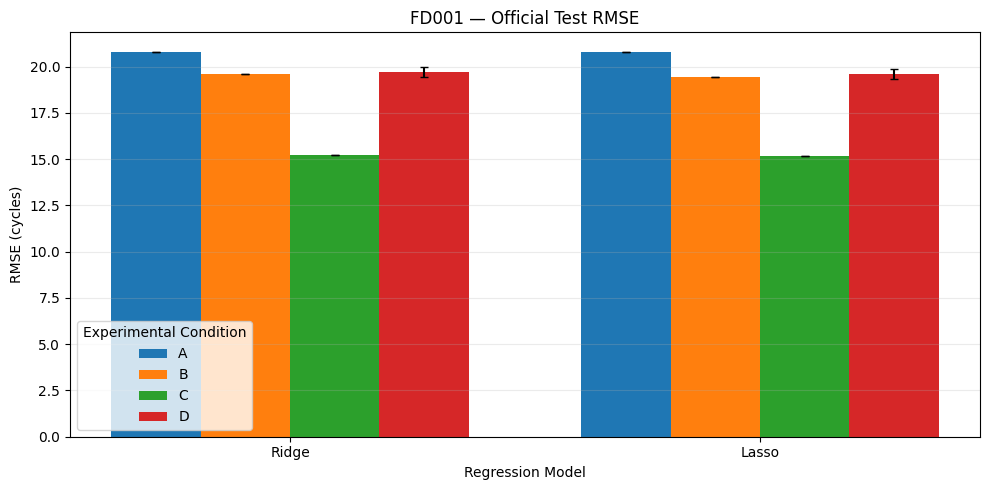

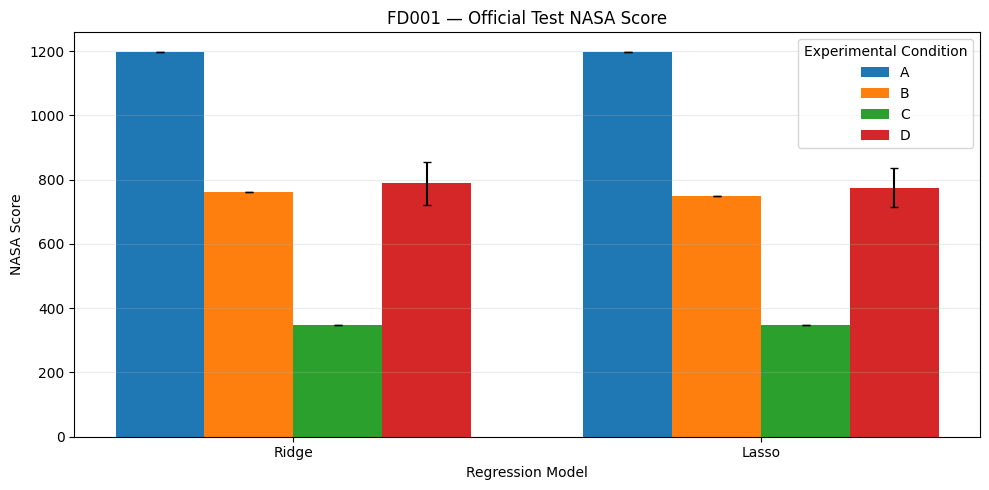

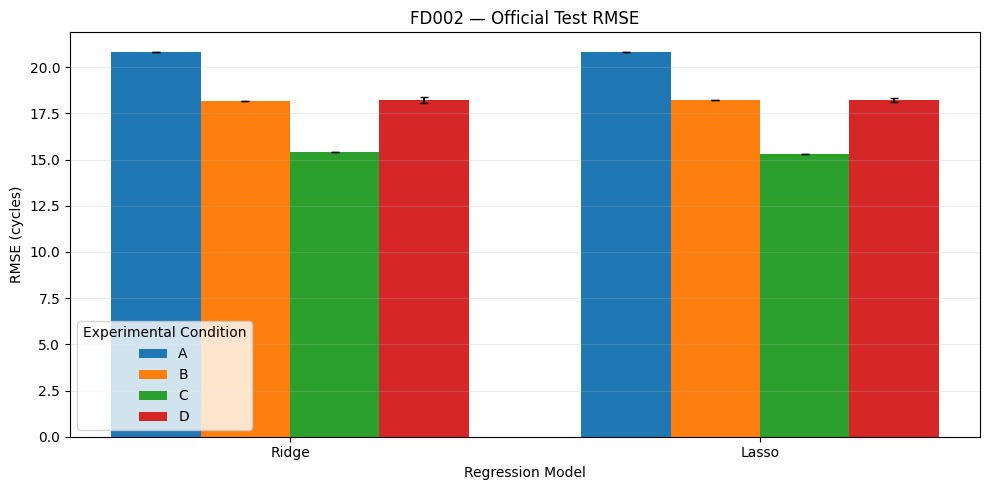

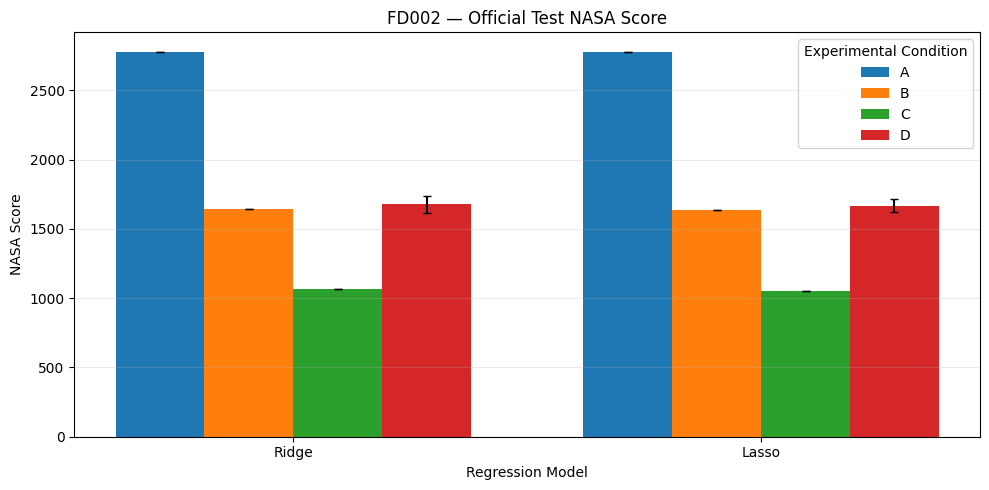

In [15]:
for ds in DATASETS:

    for metric, mean_col, sd_col, ylabel in [
        (
            "RMSE",
            "test_rmse_mean",
            "test_rmse_sd",
            "RMSE (cycles)"
        ),
        (
            "NASA Score",
            "test_nasa_mean",
            "test_nasa_sd",
            "NASA Score"
        )
    ]:

        fig, ax = plt.subplots(figsize=(10, 5))

        x_base = np.arange(len(MODELS))
        width = 0.19

        offsets = {
            "A": -1.5,
            "B": -0.5,
            "C": 0.5,
            "D": 1.5
        }

        for condition in ["A", "B", "C", "D"]:

            part = TEST_RESULTS[
                (TEST_RESULTS.dataset == ds) &
                (TEST_RESULTS.condition == condition)
            ].set_index("model").reindex(MODELS)

            x = x_base + offsets[condition] * width

            ax.bar(
                x,
                part[mean_col],
                width=width,
                yerr=part[sd_col],
                capsize=3,
                label=condition
            )

        ax.set_xticks(x_base)
        ax.set_xticklabels(MODELS)

        ax.set_title(
            f"{ds} — Official Test {metric}"
        )

        ax.set_xlabel("Regression Model")
        ax.set_ylabel(ylabel)

        ax.legend(title="Experimental Condition")
        ax.grid(axis="y", alpha=0.25)

        plt.tight_layout()

        filename = (
            f"{OUT_DIR}/{ds}_official_test_{metric.lower().replace(' ', '_')}.png"
        )

        plt.savefig(filename, dpi=150)
        plt.show()

## 9. Save the experiment outputs

Files written to `OUT_DIR`:

- `cv_fold_results.csv` — fold-level CV metrics, including shuffle repetitions.
- `cv_summary.csv` — mean and standard deviation across five folds.
- `official_test_results.csv` — final official test metrics.
- `official_test_predictions.csv` — per-engine official test predictions.
- PNG plots — CV window-length comparisons and official test comparison.

## 10. Experimental notes and interpretation

1. **Only Ridge and Lasso are trained.** No tree-based or boosting model is imported or fitted.
2. **Scaling is essential.** `StandardScaler` is fitted separately within each training fold through a scikit-learn pipeline. Validation and test data are transformed using training-fitted feature statistics.
3. **Regularization strengths are fixed in advance** (`RIDGE_ALPHA` and `LASSO_ALPHA`). They are not selected using the official test set. If alpha tuning is required, it should be done inside the training portion of each fold, not on the held-out fold or official test set.
4. **Fold consistency:** both datasets use seed 42, five folds, the same shuffle-and-round-robin assignment algorithm and fold labels 0–4. The engine membership differs because the datasets contain different engine populations.
5. **Official test evaluation:** one final fit per dataset/model/condition, using all available training engines. The official test set is not used to choose the window length.
6. **Metric direction:** lower RMSE and lower NASA score are better.